# Machine Learning Assignment 2
## Steel Plates Fault Classification

**Programme:** M.Tech Artificial Intelligence and Machine Learning  
**Institute:** BITS Pilani WILP

### Objective
To develop and compare five machine learning classification
algorithms to identify different types of steel plate faults.

### Models
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine



In [1]:
#Import libraries
# Data handling
import pandas as pd
import numpy as np

# Machine learning preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Define project paths

from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Dataset directory
DATA_DIR = PROJECT_DIR / "data"

# Model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

Project directory: /home/s2026ak05264/workspace/ML_Assignement_2
Data directory: /home/s2026ak05264/workspace/ML_Assignement_2/data
Model directory: /home/s2026ak05264/workspace/ML_Assignement_2/models


In [3]:
import pandas as pd
from pathlib import Path

In [4]:
#Load training and testing data


# Load prepared datasets
train_data = pd.read_csv(DATA_DIR / "train_data.csv")
test_data = pd.read_csv(DATA_DIR / "test_data.csv")

# Separate input features and target
X_train = train_data.drop(columns=["Target"])
y_train = train_data["Target"]

X_test = test_data.drop(columns=["Target"])
y_test = test_data["Target"]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1552, 27)
Testing data shape: (389, 27)

Training target shape: (1552,)
Testing target shape: (389,)


In [5]:
#Validate the input data

# Verify feature consistency
assert list(X_train.columns) == list(X_test.columns)

# Verify dataset dimensions
assert X_train.shape == (1552, 27)
assert X_test.shape == (389, 27)

# Verify all seven classes are present
assert y_train.nunique() == 7
assert y_test.nunique() == 7

# Verify no missing values
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

print("Dataset validation successful.")
print("All seven classes are available.")
print("No missing values found.")

Dataset validation successful.
All seven classes are available.
No missing values found.


In [6]:
#Define the five classification models

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("classifier", GaussianNB())
    ]),

    
    "Support Vector Machine": CalibratedClassifierCV(
        estimator=Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(random_state=42))
    ]),
    method="sigmoid",
    cv=5,
    ensemble=False
)
}

print("Five classification models defined successfully.")

for model_name in models:
    print("-", model_name)

Five classification models defined successfully.
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine


In [7]:
##Train all five models

trained_models = {}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print("Training completed:", model_name)

print("\nAll five models trained successfully.")


Training: Logistic Regression
Training completed: Logistic Regression

Training: Decision Tree
Training completed: Decision Tree

Training: KNN
Training completed: KNN

Training: Naive Bayes
Training completed: Naive Bayes

Training: Support Vector Machine
Training completed: Support Vector Machine

All five models trained successfully.


In [8]:
#Verify the trained models

print("TRAINED MODEL VERIFICATION")
print("-" * 40)

for model_name, model in trained_models.items():

    predictions = model.predict(X_test)

    print(f"{model_name}")
    print("Predictions generated:", len(predictions))
    print("Predicted classes:", len(np.unique(predictions)))
    print("-" * 40)

TRAINED MODEL VERIFICATION
----------------------------------------
Logistic Regression
Predictions generated: 389
Predicted classes: 7
----------------------------------------
Decision Tree
Predictions generated: 389
Predicted classes: 7
----------------------------------------
KNN
Predictions generated: 389
Predicted classes: 7
----------------------------------------
Naive Bayes
Predictions generated: 389
Predicted classes: 7
----------------------------------------
Support Vector Machine
Predictions generated: 389
Predicted classes: 7
----------------------------------------


## Stage 4: Model Evaluation and Comparison

Evaluate all five trained classification models using the
same test dataset.

Evaluation metrics:
1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

In [9]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

print("Evaluation libraries imported successfully.")

Evaluation libraries imported successfully.


In [10]:
#Calculate all six metrics

# Store evaluation results
results = []

# Fixed class order for consistent evaluation
class_labels = sorted(y_train.unique())

for model_name, model in trained_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Generate class probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=class_labels,
        multi_class="ovr",
        average="weighted"
    )

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Macro metrics for additional class-level insight
    macro_precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1
    })

print("Evaluation completed for all five models.")

Evaluation completed for all five models.


In [11]:
#11-Create the model comparison table

results_df = pd.DataFrame(results)

# Sort by weighted F1 score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display formatted results
display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.columns
        if col != "Model"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Macro Precision,Macro Recall,Macro F1
0,Support Vector Machine,0.7506,0.8974,0.7578,0.7506,0.7521,0.6769,0.7982,0.7417,0.7634
1,Decision Tree,0.7429,0.8283,0.7455,0.7429,0.7429,0.6688,0.7531,0.7559,0.7530
2,Logistic Regression,0.7275,0.9066,0.7329,0.7275,0.7277,0.6487,0.7613,0.7305,0.7418
3,KNN,0.7275,0.8941,0.7318,0.7275,0.7245,0.6548,0.7458,0.7482,0.7416
4,Naive Bayes,0.4524,0.7955,0.5741,0.4524,0.4003,0.3789,0.4315,0.4795,0.3830


In [12]:
#12 — Classification report for each model

for model_name, model in trained_models.items():

    print("\n" + "=" * 65)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 65)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

       Bumps       0.69      0.57      0.62        81
   Dirtiness       0.88      0.64      0.74        11
   K_Scratch       0.95      0.91      0.93        78
Other_Faults       0.64      0.71      0.68       135
      Pastry       0.51      0.56      0.54        32
      Stains       0.86      0.86      0.86        14
   Z_Scratch       0.80      0.87      0.84        38

    accuracy                           0.73       389
   macro avg       0.76      0.73      0.74       389
weighted avg       0.73      0.73      0.73       389


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

       Bumps       0.66      0.69      0.67        81
   Dirtiness       0.83      0.91      0.87        11
   K_Scratch       0.97      0.86      0.91        78
Other_Faults       0.69      0.72      0.70       135
      Pastry       0.48      0.41      0.44       

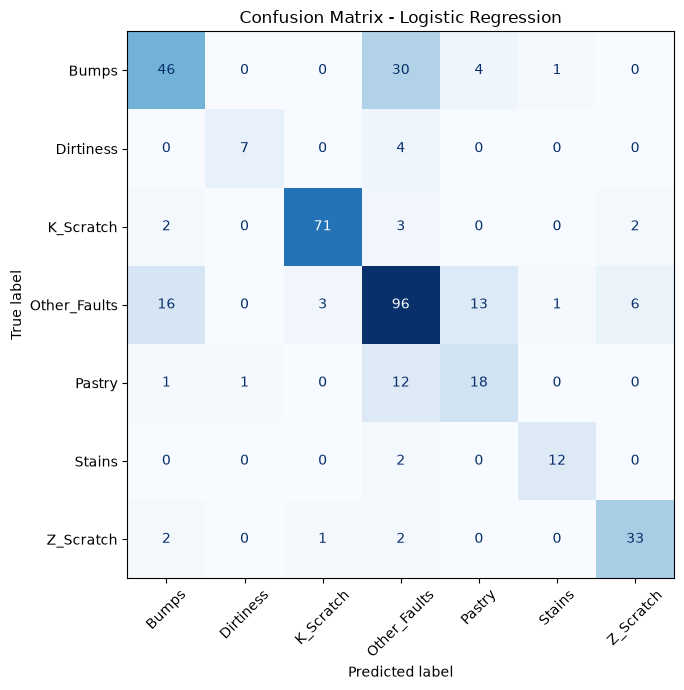

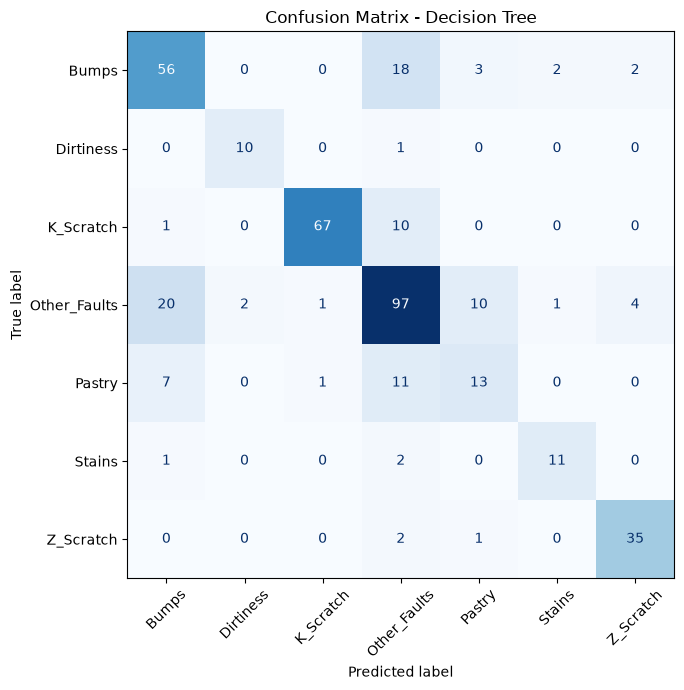

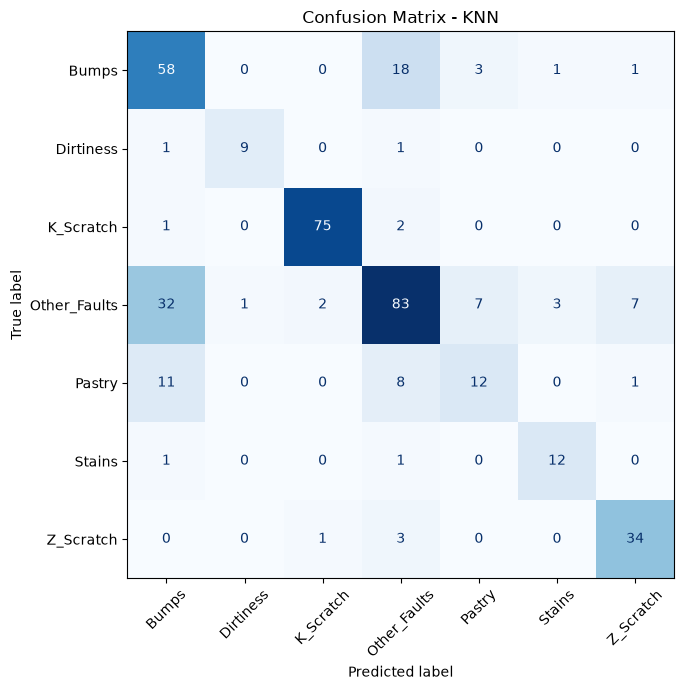

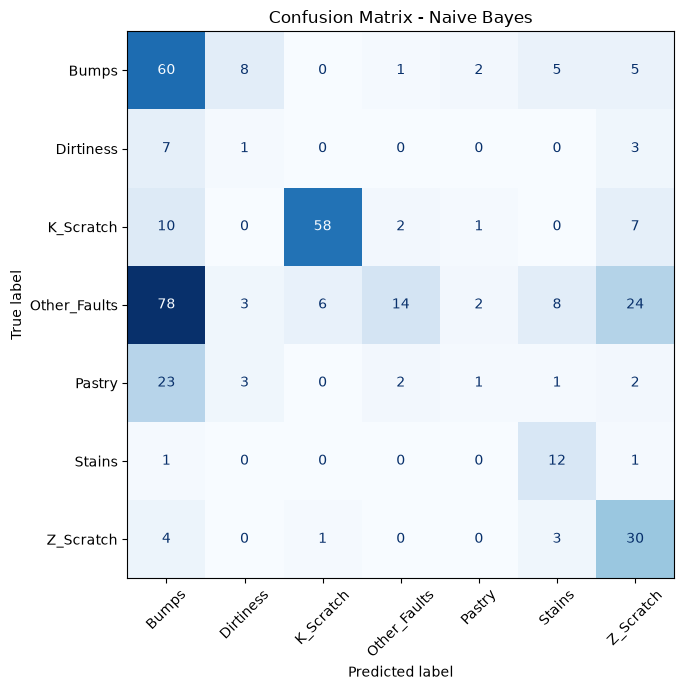

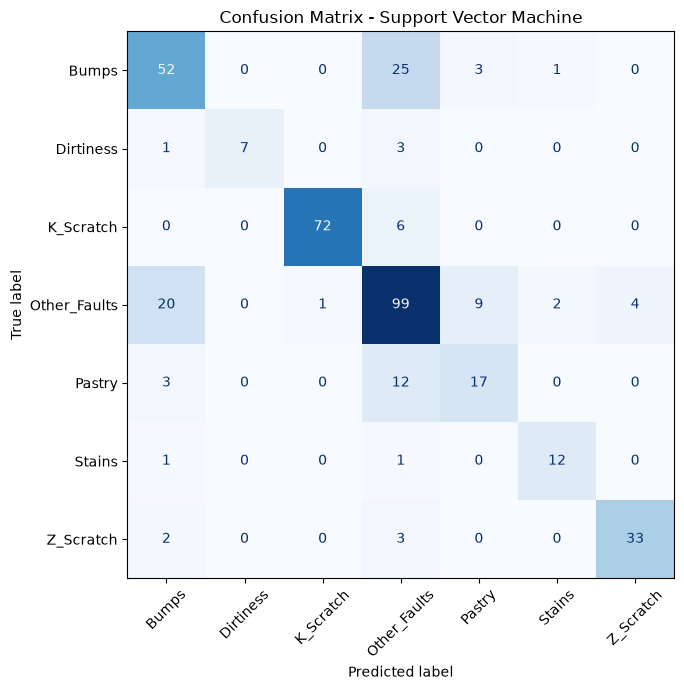

In [13]:
#13 — Confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_labels,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

## Stage 5: Model Saving and Export

Save all five trained classification pipelines and
their evaluation results for reuse in the Streamlit application.

The saved models include their preprocessing steps.

In [14]:
# Model serialization
import joblib

# File handling
import json
from pathlib import Path

print("Model-saving libraries imported successfully.")

Model-saving libraries imported successfully.


In [15]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [16]:
#Verify the model directory

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR.resolve())
print("Directory exists:", MODEL_DIR.exists())

Model directory: /home/s2026ak05264/workspace/ML_Assignement_2/models
Directory exists: True


### 5.1 Save Trained Classification Models

Each trained pipeline is saved as a separate Joblib file.

The saved pipelines include the preprocessing and
classification components required for prediction.

In [17]:
model_files = {}

for model_name, model in trained_models.items():

    # Create a safe filename
    file_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    file_path = MODEL_DIR / f"{file_name}.joblib"

    # Save trained pipeline
    joblib.dump(model, file_path)

    model_files[model_name] = str(file_path.name)

    print(f"Saved: {file_path.name}")

print("\nAll five models saved successfully.")

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: support_vector_machine.joblib

All five models saved successfully.


### 5.2 Export Model Evaluation Results

Save the evaluation metrics of all five classifiers
as a CSV file for reporting and comparison.

In [18]:
# Save complete comparison table
results_path = MODEL_DIR / "model_comparison.csv"

results_df.to_csv(results_path, index=False)

print("Evaluation results saved successfully.")
print("Location:", results_path.resolve())

display(results_df)

Evaluation results saved successfully.
Location: /home/s2026ak05264/workspace/ML_Assignement_2/models/model_comparison.csv


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Macro Precision,Macro Recall,Macro F1
0,Support Vector Machine,0.750643,0.897418,0.757832,0.750643,0.752112,0.676864,0.798151,0.741652,0.763367
1,Decision Tree,0.742931,0.828292,0.745474,0.742931,0.742884,0.668769,0.753138,0.755851,0.753028
2,Logistic Regression,0.727506,0.906643,0.732903,0.727506,0.727654,0.648680,0.761262,0.730528,0.741789
3,KNN,0.727506,0.894064,0.731797,0.727506,0.724484,0.654799,0.745843,0.748209,0.741573
4,Naive Bayes,0.452442,0.795537,0.574098,0.452442,0.400278,0.378900,0.431545,0.479544,0.382957


### 5.3 Save Classification Labels

Store the seven fault categories in a JSON file.

This will help maintain consistent class names
when the saved models are used in the application.

In [19]:
class_names = sorted(y_train.unique().tolist())

labels_path = MODEL_DIR / "class_labels.json"

with open(labels_path, "w") as file:
    json.dump(class_names, file, indent=4)

print("Class labels saved successfully.")

print("\nAvailable classes:")
for class_name in class_names:
    print("-", class_name)

Class labels saved successfully.

Available classes:
- Bumps
- Dirtiness
- K_Scratch
- Other_Faults
- Pastry
- Stains
- Z_Scratch


### 5.4 Verify Exported Model Files

Check that all five model files, evaluation results,
and class-label information exist.

In [20]:
required_files = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "support_vector_machine.joblib",
    "model_comparison.csv",
    "class_labels.json"
]

print("SAVED FILE VERIFICATION")
print("-" * 50)

for file_name in required_files:

    file_path = MODEL_DIR / file_name

    print(
        file_name,
        "->",
        "EXISTS" if file_path.exists() else "MISSING"
    )

assert all(
    (MODEL_DIR / file_name).exists()
    for file_name in required_files
)

print("\nSTAGE 5 FILE VERIFICATION PASSED")

SAVED FILE VERIFICATION
--------------------------------------------------
logistic_regression.joblib -> EXISTS
decision_tree.joblib -> EXISTS
knn.joblib -> EXISTS
naive_bayes.joblib -> EXISTS
support_vector_machine.joblib -> EXISTS
model_comparison.csv -> EXISTS
class_labels.json -> EXISTS

STAGE 5 FILE VERIFICATION PASSED


In [21]:
print("SAVED MODEL LOAD TEST")
print("-" * 50)

for model_name, original_model in trained_models.items():

    file_name = model_files[model_name]
    file_path = MODEL_DIR / file_name

    # Load saved model
    loaded_model = joblib.load(file_path)

    # Generate predictions from original and loaded models
    original_predictions = original_model.predict(X_test)
    loaded_predictions = loaded_model.predict(X_test)

    # Compare predictions
    assert np.array_equal(
        original_predictions,
        loaded_predictions
    )

    print(f"{model_name}: LOAD AND PREDICTION VERIFIED")

print("\nALL FIVE SAVED MODELS VERIFIED SUCCESSFULLY.")

SAVED MODEL LOAD TEST
--------------------------------------------------
Logistic Regression: LOAD AND PREDICTION VERIFIED
Decision Tree: LOAD AND PREDICTION VERIFIED
KNN: LOAD AND PREDICTION VERIFIED
Naive Bayes: LOAD AND PREDICTION VERIFIED
Support Vector Machine: LOAD AND PREDICTION VERIFIED

ALL FIVE SAVED MODELS VERIFIED SUCCESSFULLY.


### 5.5 Save Input Feature Information

Save the names and order of all 27 input features.
The Streamlit application will use this information
to validate uploaded test datasets.

In [22]:
feature_names = X_train.columns.tolist()

feature_path = MODEL_DIR / "feature_names.json"

with open(feature_path, "w") as file:
    json.dump(feature_names, file, indent=4)

print("Feature names saved successfully.")
print("Number of features:", len(feature_names))

Feature names saved successfully.
Number of features: 27
